In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

import os
os.environ["PATH"] = "/global/common/software/nersc9/texlive/2024/bin/x86_64-linux:" + os.environ["PATH"]

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = "Times New Roman"

import healpy as hp
import pollux

import itertools
from multiprocessing import Pool
import healsparse


In [3]:
smooth_map = True
degrade_map = False

root_dit = os.path.join(os.environ["CFS"], "lsst/shared/external/HACC-HOS-Y1/HOS_Sims")

N_part = 2048
if N_part == 2048:
    sims = ["HACC150_3", "HACC195_2"]
elif N_part == 1024:
    sims = ["HACC091_1024", "HACC106_1024"]

nside_in = 8192
theta_smooth = 5 # arcmin
nside_out = 4096 if degrade_map else nside_in

nbins = 100

xlims = np.array(list(zip(np.linspace(-0.01, -0.1, 5),
                          np.linspace(0.02, 0.2, 5))))

filename = f"data/kappaPDF_nside{nside_out}_{N_part}"
filename += "_smooth" + str(theta_smooth) if smooth_map else "_nosmooth"
npfile = filename + ".npy"

pngfile = filename.replace("data", "plots") + ".png"
pngfile_compar = filename.replace("data", "plots") + "_compar.png"

try:
    res = np.load(npfile, allow_pickle=True).item()

except:

    mask_octant = pollux.utils.make_mask_radec_cuts(
        nside_out, 0, 90, 0, 90, eps=1e-10, nest=True
    ).astype(bool)
    ipix_octant = np.where(mask_octant)[0]

    def doit(args):
        sim, nshells, seed, imap = args

        # =======================================================
        # FAST PATH → No smoothing, no degrading
        # =======================================================
        if (not smooth_map) and (not degrade_map):
            kappa_map = healsparse.HealSparseMap.read(
                os.path.join(
                    root_dir, sim,
                    f"shells_z{nshells}_subsampledensitymax1.5_nside{nside_in}",
                    "SRDv1_nz",
                    f"kappa_hacc_seed{seed}_nside{nside_in}_imap{imap}.fits"
                )
            ).generate_healpix_map()

        else:
            # =======================================================
            # GENERAL PATH → Load ALMs, optionally smooth + degrade
            # =======================================================
            alm = hp.read_alm(
                os.path.join(
                    root_dir, sim,
                    f"shells_z{nshells}_subsampledensitymax1.5_nside{nside_in}",
                    "SRDv1_nz",
                    f"kappa_hacc_seed{seed}_nside{nside_in}_alms_imap{imap}.fits"
                )
            )

            lmax_in = hp.Alm.getlmax(len(alm))
            lmax_out = 2 * nside_out

            if degrade_map:
                alm = hp.resize_alm(
                    alm,
                    lmax=lmax_in, mmax=lmax_in,
                    lmax_out=lmax_out, mmax_out=lmax_out,
                )
            else:
                lmax_out = lmax_in

            sigma = None
            if smooth_map:
                sigma = 1.88132 * theta_smooth/60 * np.pi/180 # from Lina

            kappa_map = hp.alm2map(
                alm, nside_out, lmax=lmax_out, sigma=sigma
            )

            kappa_map = hp.reorder(kappa_map, r2n=True)

        kappa_map[~mask_octant] = hp.UNSEEN

        vals = kappa_map[ipix_octant]
        vals = vals - vals.mean()
        hist = np.histogram(
            vals,
            bins=np.linspace(*xlims[imap], nbins),
            density=True
        )[0]

        print("Done!")
        return hist

    list_args = list(itertools.product(
        sims, [26, 34, 51, 101], range(5), range(5)
    ))

    if __name__ == "__main__":
        with Pool(processes=10) as pool:
            out = pool.map(doit, list_args)

    res = {k: o for k, o in zip(list_args, out)}
    np.save(npfile, res)


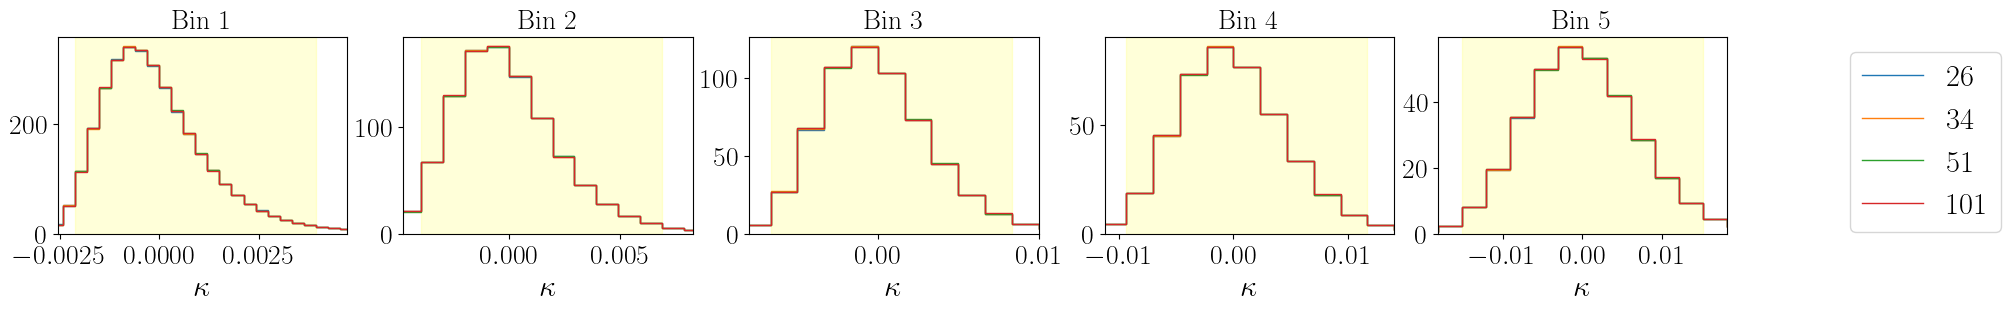

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3), layout='constrained', sharey=False)

kappa_lim = {}

for nshells in [26, 34, 51, 101]:
    for imap in range(5):
        x = [res[(sim, nshells, seed, imap)] for sim in sims for seed in range(5)]
        mean_hist = np.mean(x, axis=0)
        ax = axes[imap]

        bin_edges = np.linspace(xlims[imap][0], xlims[imap][1], nbins)

        ax.stairs(mean_hist, bin_edges, label=f'{nshells}')

        if nshells == 101:
            hist_area = mean_hist / np.sum(mean_hist)
            cdf = np.cumsum(hist_area)
            lower_idx = np.searchsorted(cdf, 0.025)
            upper_idx = np.searchsorted(cdf, 0.975)
            lower_kappa = bin_edges[lower_idx]
            upper_kappa = bin_edges[upper_idx + 1]
            ax.axvspan(lower_kappa, upper_kappa, color='yellow', alpha=0.15, zorder=0)
        
            ax.set_xlim(1.2 * lower_kappa, 1.2 * upper_kappa)

            kappa_lim[imap] = [lower_kappa, upper_kappa]

            ax.set_xlabel(r'$\kappa$', fontsize=22)
            ax.set_title(f'Bin {imap+1}', fontsize=20)
            
        ax.tick_params(axis='x', labelsize=20)
        ax.tick_params(axis='y', labelsize=20)

plt.subplot(1, 5, 5)
plt.legend(bbox_to_anchor=(2, 1), loc="upper right", fontsize=22)


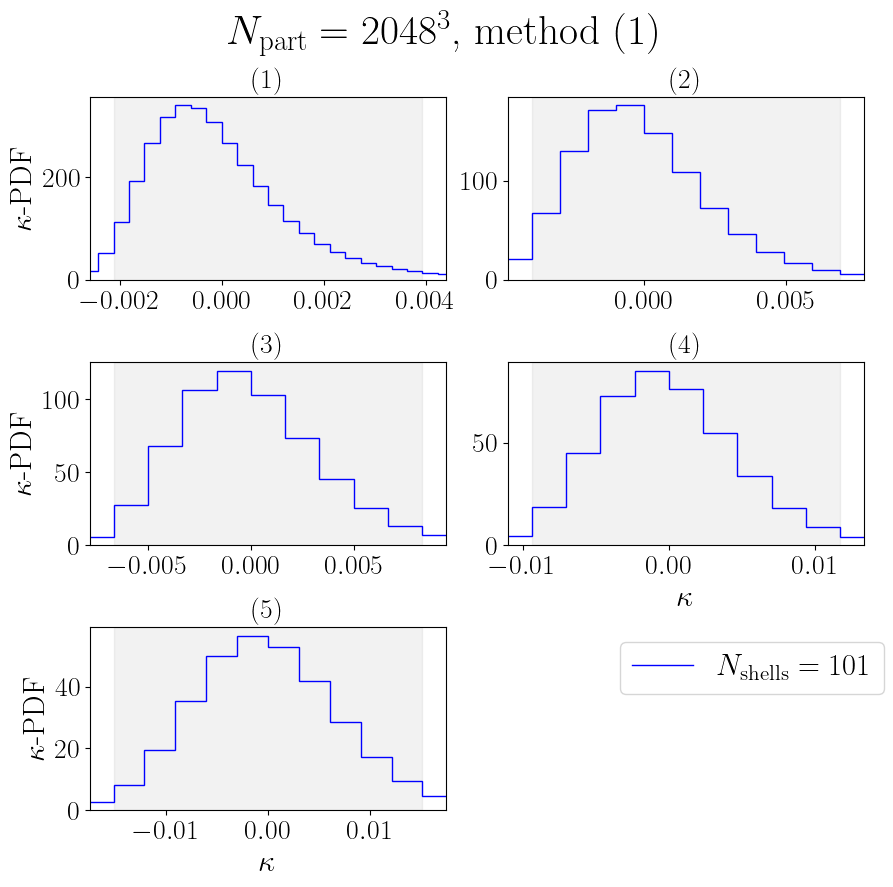

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(9, 9))

axes_flat = axes.flatten()

padding_factor = 1.15
xlims_expanded = {}

for i, (xmin, xmax) in kappa_lim.items():
    center = 0.5 * (xmin + xmax)
    half_range = 0.5 * (xmax - xmin)
    half_range_new = half_range * padding_factor
    xlims_expanded[i] = [center - half_range_new, center + half_range_new]

legend_handles = []
legend_labels  = []

for imap in range(5):
    for i, nshells in enumerate([101]):

        pdfs = [
            res[(sim, nshells, seed, imap)]
            for sim in sims
            for seed in range(5)
        ]
        m = np.mean(pdfs, axis=0)

        ax = axes_flat[imap]
        bins = np.linspace(*xlims[imap], nbins)

        h = ax.stairs(m, bins, color="blue")

        if imap == 0:
            legend_handles.append(h)
            legend_labels.append(fr"$N_{{\rm shells}}={nshells}$")

    ax.axvspan(kappa_lim[imap][0], kappa_lim[imap][1],
               color="grey", alpha=0.1, zorder=0)

    ax.set_xlim(xlims_expanded[imap])

    ax.set_title(fr'$({imap+1})$', fontsize=20)
    if imap in [3, 4]:
        ax.set_xlabel(r'$\kappa$', fontsize=22)
    if imap in [0, 2, 4]:
        ax.set_ylabel(r"$\kappa$-PDF", fontsize=22)

    ax.tick_params(axis='x', labelsize=20)
    ax.tick_params(axis='y', labelsize=20)

plt.legend(legend_handles, legend_labels, bbox_to_anchor=(1 + 0.1, 1), loc="upper right", fontsize=22)

for idx in range(5):
    ax = axes_flat[idx]
    yl = ax.get_ylim()
    a = max(abs(yl[0]), abs(yl[1]))
    ax.set_ylim(0, a)

axes_flat[5].axis("off")

fig.suptitle(fr"$N_{{\rm part}} = {N_part}^3$, method $(1)$", fontsize=30)

plt.tight_layout()
plt.savefig(pngfile.replace("png", "pdf"), bbox_inches="tight")


/tmp/ipykernel_1702415/4128426093.py:58: RuntimeWarning: invalid value encountered in divide
  h, = ax.plot((bins[:-1] + np.diff(bins) / 2)[valid], (m/std)[valid], ".-", color=colors[i])
/tmp/ipykernel_1702415/4128426093.py:58: RuntimeWarning: divide by zero encountered in divide
  h, = ax.plot((bins[:-1] + np.diff(bins) / 2)[valid], (m/std)[valid], ".-", color=colors[i])


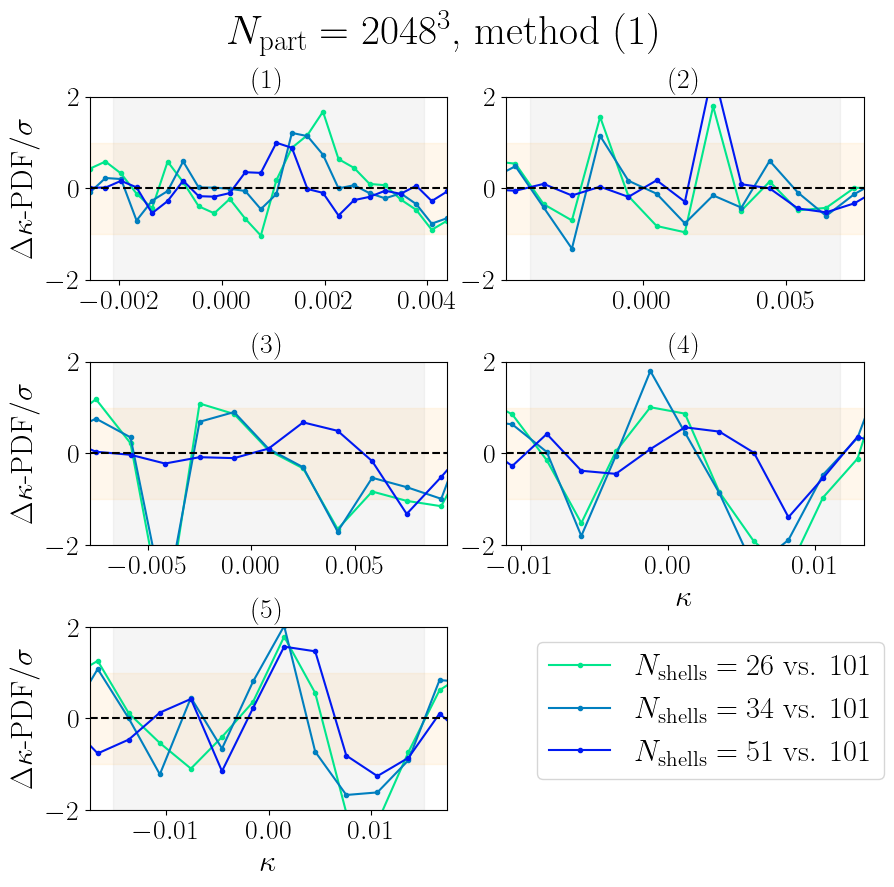

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(9, 9))

axes_flat = axes.flatten()

padding_factor = 1.15
xlims_expanded = {}

for i, (xmin, xmax) in kappa_lim.items():
    center = 0.5 * (xmin + xmax)
    half_range = 0.5 * (xmax - xmin)
    half_range_new = half_range * padding_factor
    xlims_expanded[i] = [center - half_range_new, center + half_range_new]

legend_handles = []
legend_labels  = []

colors = [
    [0.0, 0.90196078, 0.54901961, 1.0],
    [0.0, 0.49803922, 0.75098039, 1.0],
    [0.0, 0.09803922, 0.95098039, 1.0]
]

std_dict = {}
for imap in range(5):
    for nshells in [26, 34, 51, 101]:
    
        values = [res[(sim, nshells, seed, imap)]
                  for sim in sims
                  for seed in range(5)]
        
        std_dict[imap, nshells] = np.std(values, axis=0) / np.sqrt(len(values))

option = 1
option = 2

for imap in range(5):
    for i, nshells in enumerate([26, 34, 51]):

        diffs = [
            res[(sim, nshells, seed, imap)] - res[(sim, 101, seed, imap)]
            for sim in sims
            for seed in range(5)
        ]
        m = np.mean(diffs, axis=0)
        std = std_dict[imap, 101]

        ax = axes_flat[imap]
        bins = np.linspace(*xlims[imap], nbins)

        if option == 1:
            h = ax.stairs(m, bins, color=colors[i])
            ax.fill_between(bins[:-1] + np.diff(bins) / 2, m - std, m + std, alpha=0.2, color=colors[i])
        elif option == 2:
            valid = std > 1e-8
            h, = ax.plot((bins[:-1] + np.diff(bins) / 2)[valid], (m/std)[valid], ".-", color=colors[i])

        if imap == 0:
            legend_handles.append(h)
            legend_labels.append(fr"$N_{{\rm shells}}={nshells}$ vs. 101")

    ax.axvspan(kappa_lim[imap][0], kappa_lim[imap][1],
               color='grey', alpha=0.075, zorder=0)

    ax.set_xlim(xlims_expanded[imap])

    ax.set_title(fr'$({imap+1})$', fontsize=20)
    if imap in [3, 4]:
        ax.set_xlabel(r'$\kappa$', fontsize=22)
    if imap in [0, 2, 4]:
        if option == 1:
            ax.set_ylabel(r"$\Delta\kappa$-PDF", fontsize=22)
        elif option == 2:
            ax.set_ylabel(r"$\Delta\kappa$-PDF$/\sigma$", fontsize=22)

    if option == 2:
        ax.axhspan(-1, 1, color="#FFB84D", alpha=0.1)

    ax.tick_params(axis='x', labelsize=20)
    ax.tick_params(axis='y', labelsize=20)
    ax.axhline(0, color="k", ls="--")

plt.legend(legend_handles, legend_labels, bbox_to_anchor=(1 + 0.1, 1), loc="upper right", fontsize=22)

for idx in range(5):
    ax = axes_flat[idx]
    ax.set_ylim(-2, 2)

axes_flat[5].axis("off")

fig.suptitle(fr"$N_{{\rm part}} = {N_part}^3$, method $(1)$", fontsize=30)

plt.tight_layout()
plt.savefig(pngfile_compar.replace("png", "pdf"), bbox_inches="tight")
